# Energy Markets Quantitative Analysis — Lecture 5: Energy derivatives and hedging
Prof. dr. Daniel Traian Pele — Bucharest University of Economic Studies; Romanian Academy, Institute for Economic Forecasting

This notebook reproduces the numbers and charts of Lecture 5 from the real data in `../data/clean` (see `../data/SOURCES.md`, section *Lecture 5 additions*). Section numbers (§) match the *Experiment yourself* pointers on the slides.

**Data.** Romanian forward prices = OPCOM PCCB-LE-flex auction results (one closing price per traded session, lei converted to EUR with the ECB rate of the auction day). Spot = OPCOM day-ahead (PZU) prices. Gas = TTF (World Bank monthly; NYMEX single contracts), carbon = EUA, coal = World Bank. Cut-off = last complete month.

## §1 Data and the Romanian forward market

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, warnings
from scipy.stats import norm
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261106
ETA_GAS, ETA_COAL = 0.50, 0.38      # efficiencies (assumed)
EF_GAS, EF_COAL = 0.202, 0.341      # t CO2 per MWh thermal (IPCC 2006)
COAL_MWH_T = 6.978                  # MWh thermal per tonne of 6000 kcal/kg coal

PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
raw_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
FW = pd.read_csv(DATA + 'opcom_forward_trades.csv', parse_dates=['auction_date', 'delivery_start', 'delivery_end'])
FW = FW[FW['auction_date'] <= END].copy()
RATES = pd.read_csv(DATA + 'ecb_ron_estr_daily.csv', parse_dates=['date']).set_index('date')
print('cut-off:', END.date(), '| traded forward sessions:', len(FW), '| TWh:', round(FW['mwh'].sum() / 1e6, 2))
FW.head()

cut-off: 2026-10-31 | traded forward sessions: 2298 | TWh: 83.68


,auction_date,session,profile,delivery_start,delivery_end,price_ron_mwh,mw,mwh,initiator_side,seller,buyer,eurron_ecb,price_eur_mwh
0,2020-05-12,VBLD_120520_02,banda LD,2021-01-01,2021-12-31,250.60,5.0,43800.0,sell,S.C. HIDROELECTRICA S.A.,S.C. ELECTRICA FURNIZARE S.A.,4.8301,51.8830
1,2020-05-12,VBLD_120520_03,banda LD,2021-01-01,2021-12-31,250.90,5.0,43800.0,sell,S.C. HIDROELECTRICA S.A.,S.C. E-DISTRIBUTIE MUNTENIA S.A.,4.8301,51.9451
2,2020-05-12,VBLD_120520_04,banda LD,2021-01-01,2021-12-31,250.25,5.0,43800.0,sell,S.C. HIDROELECTRICA S.A.,S.C. ELECTRICA FURNIZARE S.A.,4.8301,51.8105
3,2020-05-12,VV2_120520_02,varf 2,2021-04-01,2021-06-30,250.00,5.0,7280.0,sell,S.C. ALIVE CAPITAL S.R.L.,S.C. ELECTRICA FURNIZARE S.A.,4.8301,51.7588
4,2020-05-12,VV2_120520_04,varf 2,2021-01-01,2021-12-31,285.65,5.0,29200.0,sell,S.C. ALIVE CAPITAL S.R.L.,S.C. ELECTRICA FURNIZARE S.A.,4.8301,59.1396


kind             H     M     Q      Y  other
auction_date                                
2020          0.11  0.06  0.94  12.54   1.78
2021          1.70  0.29  1.28  11.22  12.82
2022          0.09  0.26  0.42   4.88   1.79
2023          0.00  0.03  0.32   0.94   0.29
2024          1.52  0.33  0.64   6.76   8.29
2025          0.38  0.02  0.29   0.98   3.97
2026          0.49  0.15  0.37   3.45   4.30


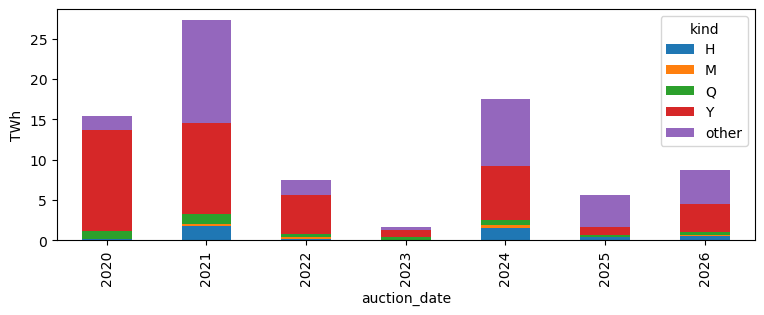

seller
SOCIETATEA COMPLEXUL ENERGETIC OLTENIA S.A.    32.5
SOCIETATEA NATIONALA NUCLEARELECTRICA S.A.     29.7
S.C. HIDROELECTRICA S.A.                       20.8
S.C. ELECTROCENTRALE BUCURESTI S.A.             3.7
S.C. ENERGY DISTRIBUTION SERVICES S.R.L.        2.2
Name: mwh, dtype: float64


In [2]:
def kind_of(s, e):
    """Standard delivery period of a product: M (month), Q (quarter), H (half-year), Y (calendar year), else 'other'."""
    if s.day != 1 or (e + pd.Timedelta(days=1)).day != 1:
        return "other"
    n = (e.year - s.year) * 12 + e.month - s.month + 1
    if n == 1:
        return "M"
    if n == 3 and s.month in (1, 4, 7, 10):
        return "Q"
    if n == 6 and s.month in (1, 7):
        return "H"
    if n == 12 and s.month == 1:
        return "Y"
    return "other"


def vwap(df):
    return float(np.average(df["price_eur_mwh"], weights=df["mwh"])) if len(df) else np.nan


def realised(s, e, col="RO"):
    """Mean day-ahead base price over [s, e] (CET days); NaN unless every day is present."""
    x = PD.loc[s:e, col]
    full = len(x) == (e - s).days + 1 and x.notna().all()
    return float(x.mean()) if full else np.nan


FW['kind'] = [kind_of(s, e) for s, e in zip(FW['delivery_start'], FW['delivery_end'])]
FW['lead_m'] = ((FW['delivery_start'].dt.year - FW['auction_date'].dt.year) * 12 + FW['delivery_start'].dt.month - FW['auction_date'].dt.month)
BASE = FW[(FW['profile'] == 'banda LD') & (FW['kind'] != 'other')].copy()
vol = FW.pivot_table(index=FW['auction_date'].dt.year, columns='kind', values='mwh', aggfunc='sum').fillna(0) / 1e6
print(vol.round(2))
vol.plot.bar(stacked=True, figsize=(9, 3)); plt.ylabel('TWh'); plt.show()
print((FW.groupby('seller')['mwh'].sum().sort_values(ascending=False).head(5) / FW['mwh'].sum() * 100).round(1))

## §2 The 2021–2022 crisis: the 2022 forward against the 2022 spot

VWAP 2022 baseload 77.39 EUR/MWh (150 auctions) | realised 2022 spot 265.30 | saving per MW-year 1646058 EUR
2020-01-01 2020-12-31 VWAP 54.39, n=23
2021-01-01 2021-06-30 VWAP 61.50, n=95
2021-07-01 2021-12-31 VWAP 136.68, n=32


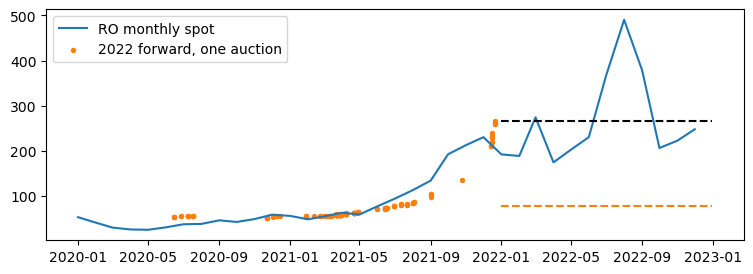

In [3]:
CY = BASE[BASE['kind'] == 'Y'].copy(); CY['dy'] = CY['delivery_start'].dt.year
c22 = CY[CY['dy'] == 2022]
S22 = realised(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31')); F22 = vwap(c22)
print('VWAP 2022 baseload %.2f EUR/MWh (%d auctions) | realised 2022 spot %.2f | saving per MW-year %.0f EUR' % (F22, len(c22), S22, (S22 - F22) * 8760))
for a0, a1 in [('2020-01-01', '2020-12-31'), ('2021-01-01', '2021-06-30'), ('2021-07-01', '2021-12-31')]:
    g = c22[(c22['auction_date'] >= a0) & (c22['auction_date'] <= a1)]; print(a0, a1, 'VWAP %.2f, n=%d' % (vwap(g), len(g)))
sm_ = PD['RO'].loc['2020':'2022'].resample('MS').mean()
fig, ax = plt.subplots(figsize=(9, 3)); ax.plot(sm_.index, sm_.values, label='RO monthly spot')
ax.scatter(c22['auction_date'], c22['price_eur_mwh'], s=8, color='C1', label='2022 forward, one auction')
ax.hlines([S22, F22], pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'), colors=['k', 'C1'], linestyles='--'); ax.legend(); plt.show()

## §3 Futures margin, the forward curve and the ex-post forward premium

In [4]:
TTFC = pd.read_csv(DATA + 'ttf_futures_contracts_daily.csv', parse_dates=['date']).set_index('date').loc[:END]
z26 = TTFC['2026-12'].dropna(); dz = z26.diff().dropna()
print('TTF Dec-2026: largest daily move %.2f EUR/MWh on %s -> margin call for 10 MW x 744 h = %.0f EUR'
      % (dz.abs().max(), dz.abs().idxmax().date(), dz.abs().max() * 7440))
CURVE_FROM = (END - pd.DateOffset(months=2) + pd.Timedelta(days=1)).normalize()
cur = BASE[(BASE['auction_date'] >= CURVE_FROM) & (BASE['delivery_start'] > END)]
print(cur.groupby(['delivery_start', 'delivery_end', 'kind']).apply(vwap).round(2))

TTF Dec-2026: largest daily move 11.83 EUR/MWh on 2022-08-29 -> margin call for 10 MW x 744 h = 88015 EUR
delivery_start  delivery_end  kind
2026-11-01      2026-11-30    M       215.33
2026-12-01      2026-12-31    M       214.27
2027-01-01      2027-01-31    M       203.04
                2027-03-31    Q       176.69
                2027-12-31    Y       148.12
2027-02-01      2027-02-28    M       201.14
2027-03-01      2027-03-31    M       159.65
dtype: float64


one-month-ahead monthly band: 30 months, mean premium 5.16 EUR/MWh, HAC t = 0.42, p = 0.677


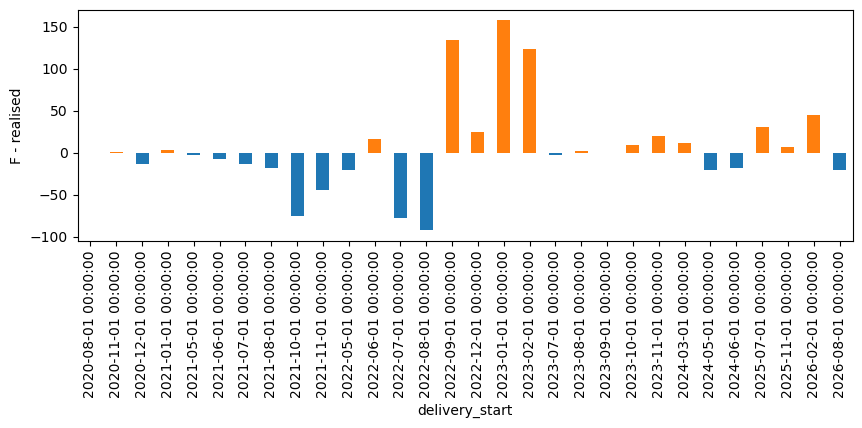

In [5]:
def premium_table(base):
    """Ex-post forward premium of every baseload product fully delivered by the cut-off: F - realised mean spot."""
    b = base[base["delivery_end"] <= END].copy()
    b["S"] = [realised(s, e) for s, e in zip(b["delivery_start"], b["delivery_end"])]
    b = b.dropna(subset=["S"])
    b["prem"] = b["price_eur_mwh"] - b["S"]
    b["lr"] = np.log(b["S"] / b["price_eur_mwh"])
    b["T"] = ((b["delivery_start"] + (b["delivery_end"] - b["delivery_start"]) / 2) - b["auction_date"]).dt.days / 365.25
    return b


def nw_t(x, lags=3):
    x = np.asarray(x, float)
    r = sm.OLS(x, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(r.params[0]), float(r.bse[0]), float(r.tvalues[0]), float(r.pvalues[0])


PT = premium_table(BASE)
M1 = PT[(PT['kind'] == 'M') & (PT['lead_m'] == 1)]
MP = M1.groupby('delivery_start').apply(lambda g: pd.Series({'F': vwap(g), 'S': g['S'].iloc[0]}))
MP['prem'] = MP['F'] - MP['S']
mu, se, tt, pp = nw_t(MP['prem'])
print('one-month-ahead monthly band: %d months, mean premium %.2f EUR/MWh, HAC t = %.2f, p = %.3f' % (len(MP), mu, tt, pp))
MP['prem'].plot.bar(figsize=(10, 3), color=np.where(MP['prem'] > 0, 'C1', 'C0')); plt.ylabel('F - realised'); plt.show()

## §4 Spark, dark and clean spreads; the gas plant as a strip of options

      CSS RO  CSS DE  CDS RO
2015  -10.83  -13.31    8.99
2016    2.79   -1.37    6.55
2017   12.79   -2.63   15.70
2018   -4.59   -6.40    0.93
2019   11.15   -1.51    4.02
2020   10.39    1.35   -4.21
2021   -4.75  -19.18   24.92
2022  -32.22  -62.25  105.96
2023  -12.49  -21.01  -12.24
2024    8.03  -16.91    8.40
2025    5.83  -13.06   10.46
2026   -0.46  -23.67   38.16


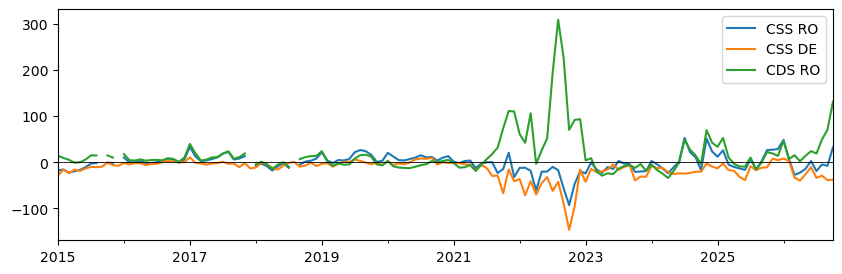

In [6]:
TTFM = pd.read_csv(DATA + 'ttf_monthly.csv'); TTFM.index = pd.PeriodIndex(TTFM['month'], freq='M').to_timestamp()
EUA = pd.read_csv(DATA + 'eua_daily.csv', parse_dates=['date']).set_index('date')
COAL = pd.read_csv(DATA + 'coal_monthly.csv'); COAL.index = pd.PeriodIndex(COAL['month'], freq='M').to_timestamp()
FUEL = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date')
m_idx = pd.date_range('2015-01-01', END.replace(day=1), freq='MS')
PM = PD[['RO', 'HU', 'DE_LU']].resample('MS').mean().reindex(m_idx)
full_m = PD[['RO', 'HU', 'DE_LU']].resample('MS').count().reindex(m_idx).eq(pd.Series(m_idx.days_in_month, index=m_idx), axis=0)
PM = PM.where(full_m)
eua_a = EUA['eua_eex_auction_eur_t'].dropna().resample('MS').mean(); eua_e = EUA['eua_etc_co2l_eur_per_unit'].dropna().resample('MS').mean()
EUAM = eua_a.reindex(m_idx).fillna(eua_e.reindex(m_idx).where(m_idx > eua_a.index.max()))
GAS = TTFM['ttf_eur_mwh'].reindex(m_idx)
COALE = (COAL['coal_southafrica_usd_t'].reindex(m_idx) / FUEL['eurusd_ecb'].resample('MS').mean().reindex(m_idx)) / COAL_MWH_T


def spreads(p, gas, coal, eua):
    """Spark, clean spark, dark and clean dark spreads in EUR per MWh of electricity."""
    ss = p - gas / ETA_GAS
    css = ss - EF_GAS / ETA_GAS * eua
    ds = p - coal / ETA_COAL
    cds = ds - EF_COAL / ETA_COAL * eua
    return ss, css, ds, cds


SPR = {z: pd.DataFrame(dict(zip(['ss', 'css', 'ds', 'cds'], spreads(PM[z], GAS, COALE, EUAM)))) for z in ['RO', 'DE_LU']}
print(pd.DataFrame({'CSS RO': SPR['RO']['css'], 'CSS DE': SPR['DE_LU']['css'], 'CDS RO': SPR['RO']['cds']}).groupby(lambda x: x.year).mean().round(2))
pd.DataFrame({'CSS RO': SPR['RO']['css'], 'CSS DE': SPR['DE_LU']['css'], 'CDS RO': SPR['RO']['cds']}).plot(figsize=(10, 3)); plt.axhline(0, color='k', lw=0.6); plt.show()

In [7]:
HP = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
HP.index = HP.index.tz_convert('Europe/Brussels')
H0 = (END - pd.DateOffset(months=12) + pd.Timedelta(days=1)).normalize()
HH = HP.loc[str(H0.date()):str(END.date())].copy(); HH['w'] = HH['mtu_minutes'] / 60.0   # hour-equivalents
cost = GAS / ETA_GAS + EF_GAS / ETA_GAS * EUAM
HH['c'] = cost.reindex(HH.index.tz_localize(None).to_period('M').to_timestamp()).values
for z in ['RO', 'DE_LU']:
    s = (HH[z] - HH['c']).dropna(); w = HH.loc[s.index, 'w']
    print(z, 'in the money %.1f%% of hours | must-run %.0f EUR/MW | flexible %.0f EUR/MW' % (100 * w[s > 0].sum() / w.sum(), (s * w).sum(), (np.maximum(s, 0) * w).sum()))

RO in the money 58.2% of hours | must-run 38095 EUR/MW | flexible 235494 EUR/MW
DE_LU in the money 40.9% of hours | must-run -165206 EUR/MW | flexible 112724 EUR/MW


## §5 Minimum-variance hedge ratio, basis risk and shape risk

HU h* = 0.966 (HAC s.e. 0.023), bootstrap 95% [0.93; 1.03], R2 = 0.979 | h* 2015-2020 = 0.92, variance cut from 2021: 97.9%


DE_LU h* = 0.875 (HAC s.e. 0.049), bootstrap 95% [0.73; 1.01], R2 = 0.796 | h* 2015-2020 = 0.91, variance cut from 2021: 81.1%
        RO-HU   RO-DE
count  138.00  138.00
mean    -2.08   13.95
std      4.55   15.25
min    -15.60  -10.49
25%     -3.62    4.17
50%     -1.41    9.15
75%      0.16   19.14
max     12.12   77.44


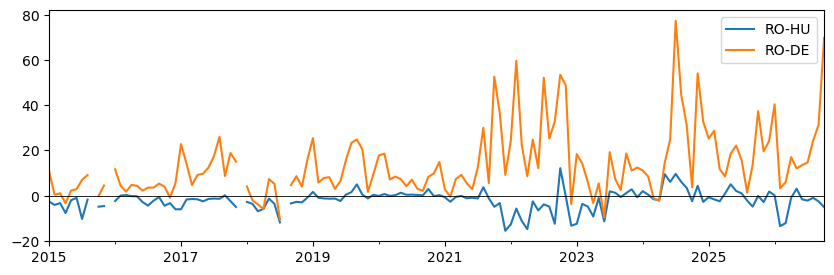

In [8]:
def hedge_ratio(dS, dF, B=2000, block=6, seed=SEED):
    """h* = Cov(dS, dF)/Var(dF) by OLS; HAC (Newey-West, 3 lags) standard error; moving-block bootstrap 95% interval."""
    X = sm.add_constant(dF.values)
    r = sm.OLS(dS.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    rng = np.random.default_rng(seed)
    n = len(dS)
    hs = []
    for _ in range(B):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.integers(0, n - block + 1, size=n // block + 1)])[:n]
        a, b = dS.values[idx], dF.values[idx]
        hs.append(np.cov(a, b)[0, 1] / np.var(b, ddof=1))
    lo, hi = np.percentile(hs, [2.5, 97.5])
    return {"h": float(r.params[1]), "se": float(r.bse[1]), "lo": float(lo), "hi": float(hi), "r2": float(r.rsquared),
            "rho": float(np.corrcoef(dS, dF)[0, 1]), "n": int(n)}


dP = PM.diff().dropna()
for z in ['HU', 'DE_LU']:
    r = hedge_ratio(dP['RO'], dP[z]); h_in = hedge_ratio(dP.loc[:'2020-12-01', 'RO'], dP.loc[:'2020-12-01', z])['h']
    oos = dP.loc['2021-01-01':]
    vr = 1 - (oos['RO'] - h_in * oos[z]).var() / oos['RO'].var()
    print(z, 'h* = %.3f (HAC s.e. %.3f), bootstrap 95%% [%.2f; %.2f], R2 = %.3f | h* 2015-2020 = %.2f, variance cut from 2021: %.1f%%'
          % (r['h'], r['se'], r['lo'], r['hi'], r['r2'], h_in, 100 * vr))
BAS = pd.DataFrame({'RO-HU': PM['RO'] - PM['HU'], 'RO-DE': PM['RO'] - PM['DE_LU']})
print(BAS.describe().round(2)); BAS.plot(figsize=(10, 3)); plt.axhline(0, color='k', lw=0.6); plt.show()

         base   load_w  solar_w  f_load  f_solar
y                                               
2015   36.370   37.612   39.494   1.034    1.086
2016   33.164   34.449   33.466   1.039    1.009
2017   48.074   50.568   52.628   1.052    1.095
2018   46.377   48.049   48.629   1.036    1.049
2019   50.409   52.368   52.666   1.039    1.045
2020   39.488   41.700   36.400   1.056    0.922
2021  111.752  115.577  100.611   1.034    0.900
2022  265.294  271.571  263.977   1.024    0.995
2023  103.738  108.469   83.167   1.046    0.802
2024  103.522  110.695   67.997   1.069    0.657
2025  108.164  115.295   64.421   1.066    0.596
2026  137.440  145.051   86.347   1.055    0.628


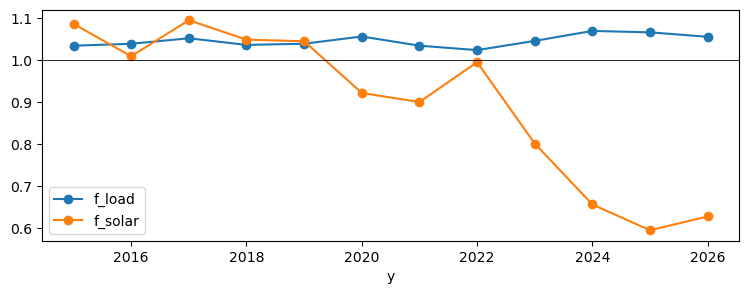

In [9]:
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
PH = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
J = pd.concat([PH['RO'], GH['load'], GH['solar']], axis=1).loc[:str(END.date()) + ' 21:00'].dropna()
J = J[J.index >= '2015-01-05']; J['y'] = J.index.tz_convert('Europe/Brussels').year


def profile_factor(g):
    base = g["RO"].mean()
    return pd.Series({"base": base, "load_w": (g["RO"] * g["load"]).sum() / g["load"].sum(),
                      "solar_w": (g["RO"] * g["solar"]).sum() / g["solar"].sum() if g["solar"].sum() > 0 else np.nan})


PF = J.groupby('y').apply(profile_factor); PF['f_load'] = PF['load_w'] / PF['base']; PF['f_solar'] = PF['solar_w'] / PF['base']
print(PF.round(3)); PF[['f_load', 'f_solar']].plot(marker='o', figsize=(9, 3)); plt.axhline(1, color='k', lw=0.6); plt.show()

## §6 Options: Black-76 with real inputs, volatility estimates, the Samuelson effect

In [10]:
def black76(F, K, T, r, sigma, kind="call"):
    """Black (1976) price of a European option on a forward/futures F; returns price, delta, vega (per 1 vol point)."""
    d1 = (np.log(F / K) + 0.5 * sigma ** 2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    disc = np.exp(-r * T)
    if kind == "call":
        p, delta = disc * (F * norm.cdf(d1) - K * norm.cdf(d2)), disc * norm.cdf(d1)
    else:
        p, delta = disc * (K * norm.cdf(-d2) - F * norm.cdf(-d1)), -disc * norm.cdf(-d1)
    vega = disc * F * norm.pdf(d1) * np.sqrt(T) / 100
    return float(p), float(delta), float(vega), float(d1), float(d2)


def ann_vol(s, window=None):
    """Annualised volatility of daily log returns between consecutive trading days (gaps <= 4 calendar days)."""
    s = s.dropna()
    r_ = np.log(s).diff().dropna()
    gap = s.index.to_series().diff().dt.days.reindex(r_.index)
    r_ = r_[gap <= 4]
    return r_ if window is None else r_.rolling(window).std() * np.sqrt(252)


def cal_vol(g, max_gap=30):
    """Volatility of a calendar forward from irregular auction days: daily VWAP, sigma^2 = sum (d ln F)^2 / sum dt,
    using only pairs of auction days at most max_gap calendar days apart."""
    dv = g.groupby("auction_date").apply(vwap)
    dl = np.log(dv).diff().dropna()
    dt = dv.index.to_series().diff().dt.days.dropna() / 365.25
    m = dt <= max_gap / 365.25
    return dl[m], dt[m]


CY_ = CY  # calendar-year baseload auctions
DL, DT = [], []
for y in [END.year - 1, END.year, END.year + 1]:
    dl, dt = cal_vol(CY_[CY_['dy'] == y]); DL.append(dl); DT.append(dt)
sig_cal = np.sqrt(sum((x ** 2).sum() for x in DL) / sum(x.sum() for x in DT))
sig_gas = ann_vol(TTFC['2027-01']).iloc[-60:].std() * np.sqrt(252)
z = M1['lr'] / np.sqrt(M1['T']); sig_term = z.std(ddof=1)
print('sigma: Romanian yearly forwards %.3f | TTF Jan-2027, 60 days %.3f | monthly spot vs forward %.3f' % (sig_cal, sig_gas, sig_term))
F0 = vwap(cur[cur['kind'] == 'Y']); r0 = RATES['estr_pct'].loc[:END].dropna().iloc[-1] / 100
T0 = (pd.Timestamp(f'{END.year}-12-15') - END).days / 365.25
for lab, sg in [('yearly forwards', sig_cal), ('TTF gas', sig_gas)]:
    c = black76(F0, F0, T0, r0, sg, 'call'); p = black76(F0, F0, T0, r0, sg, 'put')
    print('%-16s F=%.2f T=%.3f r=%.2f%% -> call %.2f put %.2f delta %.3f vega %.3f | cap 1.1F %.2f, floor 0.9F %.2f'
          % (lab, F0, T0, 100 * r0, c[0], p[0], c[1], c[2], black76(F0, 1.1 * F0, T0, r0, sg)[0], black76(F0, 0.9 * F0, T0, r0, sg, 'put')[0]))

sigma: Romanian yearly forwards 0.220 | TTF Jan-2027, 60 days 0.499 | monthly spot vs forward 0.668
yearly forwards  F=148.12 T=0.123 r=2.44% -> call 4.55 put 4.55 delta 0.514 vega 0.207 | cap 1.1F 0.63, floor 0.9F 0.43
TTF gas          F=148.12 T=0.123 r=2.44% -> call 10.30 put 10.30 delta 0.533 vega 0.206 | cap 1.1F 4.99, floor 0.9F 4.11


2026-12 last 12 months 63.0%, 2022 66.1%
2027-01 last 12 months 61.2%, 2022 67.8%
2027-02 last 12 months 67.7%, 2022 69.2%
2027-05 last 12 months 47.7%, 2022 66.8%


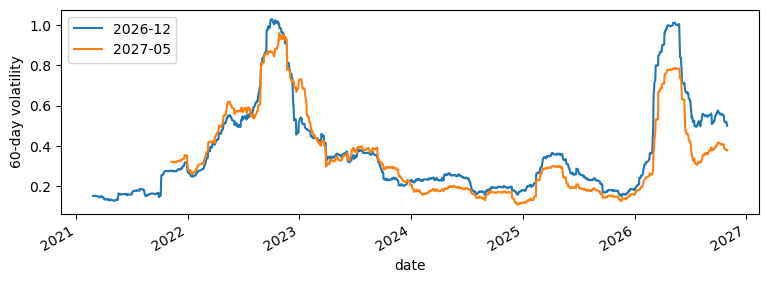

In [11]:
W12 = (END - pd.DateOffset(months=12) + pd.Timedelta(days=1)).normalize()
for col in TTFC.columns:
    r_ = ann_vol(TTFC[col]); print(col, 'last 12 months %.1f%%, 2022 %.1f%%' % (r_.loc[W12:END].std() * np.sqrt(252) * 100, r_.loc['2022'].std() * np.sqrt(252) * 100))
pd.DataFrame({c: ann_vol(TTFC[c], 60) for c in ['2026-12', '2027-05']}).plot(figsize=(9, 3)); plt.ylabel('60-day volatility'); plt.show()

## §7 Case study: a Romanian supplier in the current year, and a producer

        mean     sd     max  EUR per MW
spot  137.47  44.39  239.32  1002955.56
fwd   111.70   0.00  111.70   814946.41
half  124.58  22.20  175.51   908950.99
cap   133.64  13.94  148.47   975019.43


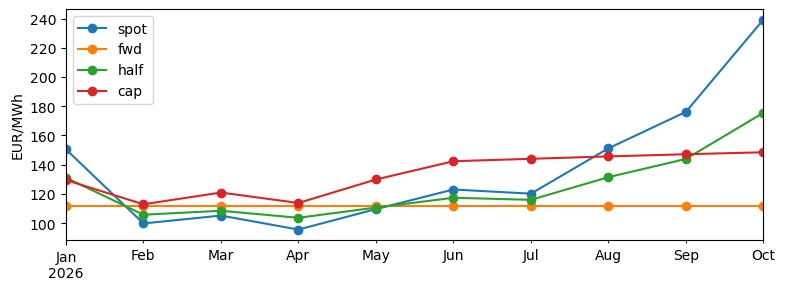

producer, 2025: sold forward at VWAP 102.13 vs realised 108.16 EUR/MWh


In [12]:
c26 = CY[CY['dy'] == END.year]; F26 = vwap(c26)
mm = pd.date_range(f'{END.year}-01-01', END.replace(day=1), freq='MS')
S26 = pd.Series([realised(m, m + pd.offsets.MonthEnd(0)) for m in mm], index=mm)
hrs = pd.Series([((m + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)).tz_localize('Europe/Brussels') - m.tz_localize('Europe/Brussels')) / pd.Timedelta(hours=1) for m in mm], index=mm)
ref = c26[c26['auction_date'] >= pd.Timestamp(f'{END.year - 1}-10-01')]; Fref = vwap(ref)
BUYD = pd.Timestamp(f'{END.year - 1}-12-15'); rb = RATES['estr_pct'].loc[:BUYD].dropna().iloc[-1] / 100
prem_m = pd.Series([black76(Fref, Fref, ((m + pd.Timedelta(days=14)) - BUYD).days / 365.25, rb, sig_term)[0] for m in mm], index=mm)
ST = pd.DataFrame({'spot': S26, 'fwd': F26, 'half': 0.5 * F26 + 0.5 * S26, 'cap': S26 - np.maximum(S26 - Fref, 0) + prem_m})
w = hrs / hrs.sum()
print(pd.DataFrame({'mean': (ST.mul(w, axis=0)).sum(), 'sd': ST.std(), 'max': ST.max(), 'EUR per MW': ST.mul(hrs, axis=0).sum()}).round(2))
ST.plot(marker='o', figsize=(9, 3)); plt.ylabel('EUR/MWh'); plt.show()
c25 = CY[CY['dy'] == END.year - 1]; S25 = realised(pd.Timestamp(f'{END.year - 1}-01-01'), pd.Timestamp(f'{END.year - 1}-12-31'))
print('producer, %d: sold forward at VWAP %.2f vs realised %.2f EUR/MWh' % (END.year - 1, vwap(c25), S25))

**Try it.** Change the hedge share (e.g. 70%), the cap strike (e.g. 1.1 × Fref) or the volatility, and see how the mean cost and its month-to-month standard deviation move.